In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex
from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors


#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Extract_X_Values_At_Specific_Y_Value
from scientific_utils.battery.plotting import Matplotlib_Overview_With_Colormap
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.general.plotting import Matplotlib_X1Y1_X2Y2

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the saved lists from the .pkl files ########

########## Open the OCV steps before the CP step
##### OCVs before a Charging step in the C Rate Test
#with open('../data/Batt15/processed/list_of_dataframes_of_OCV_before_CP_step_charge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_before_CP_step_charge = pickle.load(f)

##### OCVs before a Discharging step in the C Rate Test
#with open('../data/Batt15/processed/list_of_dataframes_of_OCV_before_CP_step_discharge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_before_CP_step_discharge = pickle.load(f)  

    
########## save the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge = pickle.load(f) 

    
########## save the OCV steps after the CP step
##### OCVs after a Charging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_charge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_charge = pickle.load(f) 

##### OCVs after a Discharging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_discharge = pickle.load(f) 


########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = [0.10, 0.33, 1.00]


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 3 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    #"pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    "pgf.rcfonts": True,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
################### Plotting of the charging functions ####################

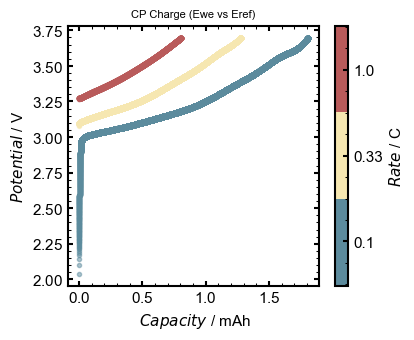

In [9]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_charge
x_values_column_name = 'Q charge/mA.h'
y_values_column_name = 'Ewe-Ece/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = 1
name_figure = 'CP_Charge_Ewe_vs_Eref'
legend_title = 'CP Charge (Ewe vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

Capacities for Potential cap at Rate 0.1 C
3p measurement: nan
2p measurement: 1.4807575257787418
Capacities for Potential cap at Rate 0.33 C
3p measurement: nan
2p measurement: 0.9682759392125655
Capacities for Potential cap at Rate 1.0 C
3p measurement: nan
2p measurement: 0.4983171495313068


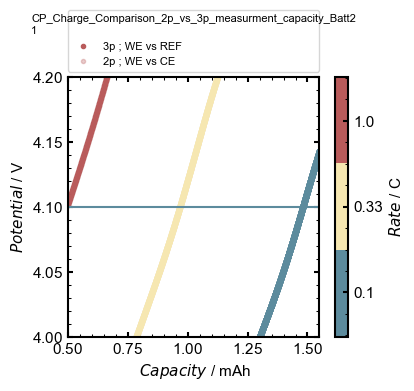

  Capacity / mAh Capacity / mAh/g Rate / C
0            NaN              NaN      0.1
1            NaN              NaN     0.33
2            NaN              NaN      1.0
  Capacity / mAh Capacity / mAh/g Rate / C
0       1.480758       176.280658      0.1
1       0.968276       115.270945     0.33
2       0.498317         59.32347      1.0


In [10]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_charge
x_values_column_name = 'Q charge/mA.h'
y1_values_column_name = '<Ewe>/V'
y2_values_column_name = 'Ewe-Ece/V'
y_cap_for_comparison = 4.1
y_ax_label = r' $ Potential $ / V  '
y_ax_limits = (4.0, 4.2) 
x_ax_label = r' $ Capacity $ / mAh '
x_ax_limits = (0.50, 1.55)
save = 1
name_figure = 'CP_Charge_Comparison_2p_vs_3p_measurment_capacity_Batt21'
legend_title = 'CP Charge (Ewe vs Eref)'

dataframe_of_capacity_until_potential_cap_3p, dataframe_of_capacity_until_potential_cap_2p = Extract_X_Values_At_Specific_Y_Value(list_of_dataframes, x_values_column_name, y1_values_column_name, y2_values_column_name, y_cap_for_comparison, y_ax_label, y_ax_limits, x_ax_label, x_ax_limits, save, name_figure, legend_title, list_RateTest_labels)

print(dataframe_of_capacity_until_potential_cap_3p)
print(dataframe_of_capacity_until_potential_cap_2p)

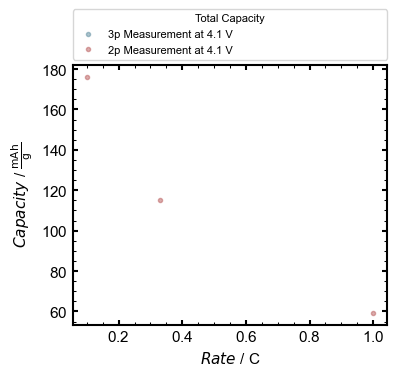

In [11]:
dataframe1 = dataframe_of_capacity_until_potential_cap_3p
dataframe2 = dataframe_of_capacity_until_potential_cap_2p
x1_values_column_name = 'Rate / C'
x2_values_column_name = 'Rate / C'
y1_values_column_name = 'Capacity / mAh/g'
y2_values_column_name = 'Capacity / mAh/g'
label_y_first = '3p Measurement at 4.1 V'
label_y_second ='2p Measurement at 4.1 V'
y_ax_label = r'$ Capacity $ / $\frac{\mathsf{mAh}}{\mathsf{g}}$'
x_ax_label = r'$ Rate $ / C'
save = 1
name_figure = 'Total_Capacity_between_2p_and_3p_charge_Batt21'
legend_title = 'Total Capacity'
    
Matplotlib_X1Y1_X2Y2(dataframe1, dataframe2, x1_values_column_name, x2_values_column_name, y1_values_column_name, y2_values_column_name, label_y_first, label_y_second, y_ax_label, x_ax_label, save, name_figure, legend_title)

In [12]:
################### Plotting of the discharging functions ####################

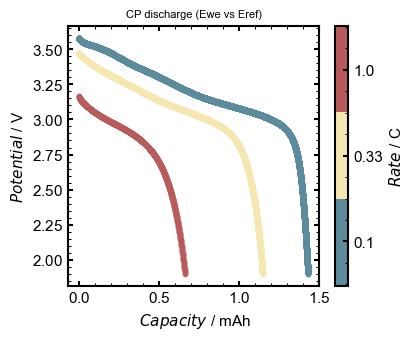

In [13]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_discharge
x_values_column_name = 'Q discharge/mA.h'
y_values_column_name = '<Ewe>/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = -1 
name_figure = 'CP_discharge_Ewe_vs_Eref'
legend_title = 'CP discharge (Ewe vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

Capacities for Potential cap at Rate 0.1 C
3p measurement: 1.3700678365098105
2p measurement: 1.4189397686659688
Capacities for Potential cap at Rate 0.33 C
3p measurement: 1.0396593146853976
2p measurement: 1.1306827156632036
Capacities for Potential cap at Rate 1.0 C
3p measurement: 0.496782043365517
2p measurement: 0.6398946267587168


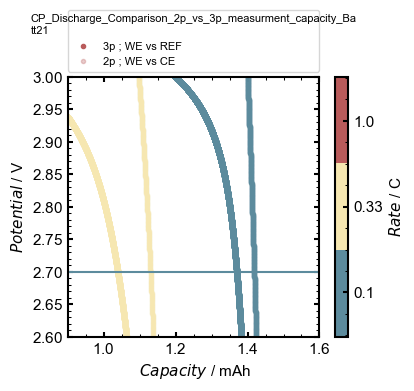

  Capacity / mAh Capacity / mAh/g Rate / C
0       1.370068       163.103314      0.1
1       1.039659       123.768966     0.33
2       0.496782        59.140719      1.0
  Capacity / mAh Capacity / mAh/g Rate / C
0        1.41894       168.921401      0.1
1       1.130683       134.605085     0.33
2       0.639895        76.177932      1.0


In [14]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_discharge
x_values_column_name = 'Q discharge/mA.h'
y1_values_column_name = '<Ewe>/V'
y2_values_column_name = 'Ewe-Ece/V'
y_cap_for_comparison = 2.7
y_ax_label = r' $ Potential $ / V  '
y_ax_limits = (2.6, 3.0) 
x_ax_label = r' $ Capacity $ / mAh '
x_ax_limits = (0.90, 1.6)
save = 1
name_figure = 'CP_Discharge_Comparison_2p_vs_3p_measurment_capacity_Batt21'
legend_title = 'CP Discharge (Ewe vs Eref)'

dataframe_of_capacity_until_potential_cap_3p_discharge, dataframe_of_capacity_until_potential_cap_2p_discharge = Extract_X_Values_At_Specific_Y_Value(list_of_dataframes, x_values_column_name, y1_values_column_name, y2_values_column_name, y_cap_for_comparison, y_ax_label, y_ax_limits, x_ax_label, x_ax_limits, save, name_figure, legend_title, list_RateTest_labels)

print(dataframe_of_capacity_until_potential_cap_3p_discharge)
print(dataframe_of_capacity_until_potential_cap_2p_discharge)

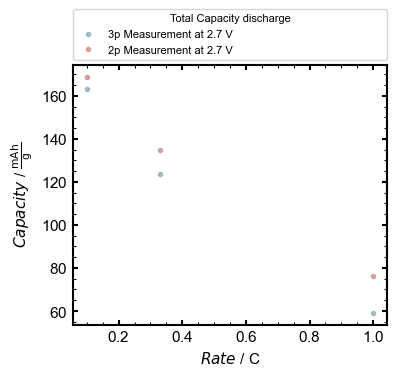

In [15]:
dataframe1 = dataframe_of_capacity_until_potential_cap_3p_discharge
dataframe2 = dataframe_of_capacity_until_potential_cap_2p_discharge
x1_values_column_name = 'Rate / C'
x2_values_column_name = 'Rate / C'
y1_values_column_name = 'Capacity / mAh/g'
y2_values_column_name = 'Capacity / mAh/g'
label_y_first = '3p Measurement at 2.7 V'
label_y_second ='2p Measurement at 2.7 V'
y_ax_label = r'$ Capacity $ / $\frac{\mathsf{mAh}}{\mathsf{g}}$'
x_ax_label = r'$ Rate $ / C'
save = 1
name_figure = 'Total_Capacity_between_2p_and_3p_discharge_Batt21'
legend_title = 'Total Capacity discharge'
    
Matplotlib_X1Y1_X2Y2(dataframe1, dataframe2, x1_values_column_name, x2_values_column_name, y1_values_column_name, y2_values_column_name, label_y_first, label_y_second, y_ax_label, x_ax_label, save, name_figure, legend_title)